# 🏥 Sổ Tay 03: Thư Viện Trực Quan Hóa Phát Hiện Toàn Bộ 84 Ca Kiểm Thử (All-Case Visual Detection Gallery)
## Comprehensive Visual Inspection of Ground Truth vs AI Detection across ALL 84 Scenarios (48 Baseline + 36 Clinical Scenarios)
*(Nền tảng mô phỏng Godot 4 Forward+ Vulkan & Backend Suy Luận Đa Mô Hình Thời Gian Thực)*

---

### 🎯 Mục Tiêu Của Sổ Tay Nghiên Cứu
Khác với **Notebook 01** (phân tích chỉ số vĩ mô 50 hạng mục) và **Notebook 02** (phân tầng nhân khẩu học và hồi quy lâm sàng 65 hạng mục), **Notebook 03 là Thư Viện Thị Giác Thực Nghiệm Tối Thượng**:
- Trực quan hóa **100% toàn bộ 84 ca kiểm thử độc lập** trong hệ sinh thái dữ liệu mô phỏng bệnh viện số hóa:
  - **Dataset 1 (`vision_eval_1200`)**: Toàn bộ **48 kịch bản baseline** ($C_{01} \to C_{48}$) trên 8 trục không gian ($D_1 \to D_8$).
  - **Dataset 2 (`vision_eval_extended_10800`)**: Toàn bộ **36 ca lâm sàng khắc nghiệt** ($N_{1.1} \to N_{6.5}$) trên 6 nhóm kịch bản ($N_1 \to N_6$).
- Soi thấu từng khung hình: Đối sánh trực quan **Ground Truth (Vết thực tế 3D/2D)** đối chiếu với **AI Prediction Bounding Boxes** của 4 mô hình:
  1. `yolov8n.pt` (Baseline — TaskAligned DFL, Greedy NMS)
  2. `yolo11n.pt` (C3k2 Block, Spatial Attention C2PSA)
  3. `yolo26n.pt` (End-to-End NMS-Free Dual-label Assignment)
  4. `intel/person-retail-0013` (OpenVINO IR MobileNetV2-SSD Clustered Anchors)
- Kết xuất **Master Scorecard Heatmap 84 Ca $\times$ 4 Mô Hình**, thư viện so sánh đối đầu đa mô hình (Head-to-Head), và hệ thống đo xa Telemetry HUD phục vụ kiểm chứng firmware điều khiển robot bệnh viện.

---

### 📐 Quy Ước Thị Giác Bounding Box & Telemetry HUD
- 🟦 **Ground Truth (GT)**: Khung nét đứt màu xanh Cyan (`#00FFFF`), kèm nhãn danh tính, khoảng cách Euclid $d$ (mét), và tỷ lệ diện tích nhìn thấy $V_{\text{vis}}$ (%).
- 🟩 **True Positive (TP)**: Khung nét liền màu xanh Neon (`#00FF66`), kèm nhãn độ tin cậy $\text{conf}$ (%), chỉ số giao cắt $\text{IoU}$, và sai số góc phương vị $\Delta\theta$ (độ).
- 🟥 **False Positive (FP - Báo Động Giả)**: Khung nét liền màu đỏ rực (`#FF3333`), cảnh báo ảo giác nhận diện nhầm trên các bẫy đạo cụ rỗng hoặc poster phẳng.
- 🟧 **False Negative (FN - Trượt Mục Tiêu)**: Khung nét đứt màu cam cảnh báo đối tượng bệnh nhân bị mô hình bỏ sót hoàn toàn.


In [1]:
import os
import sys
import json
import time
import math
from pathlib import Path

# Giới hạn phân luồng tối ưu hóa CPU inference
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = ""
try:
    import torch
    torch.set_num_threads(1)
except Exception:
    pass

import cv2
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

# Cấu hình thẩm mỹ khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
mpl.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
mpl.rcParams['figure.dpi'] = 130
mpl.rcParams['axes.titlesize'] = 10
mpl.rcParams['axes.labelsize'] = 9

# Tự động định vị Root thư mục dự án
cwd = Path.cwd()
if (cwd / 'sim_vision').exists():
    REPO_ROOT = cwd
elif (cwd.parent / 'sim_vision').exists():
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = Path('/home/bush/Projects/Data-Science-Major-Project')

if str(REPO_ROOT / 'sim_vision/python') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'sim_vision/python'))

from detector import YoloDetector, IntelOpenVINODetector

print(f"✅ REPO_ROOT xác định: {REPO_ROOT}")

# Khởi tạo CẢ 4 MÔ HÌNH THỊ GIÁC ĐỐI CHỨNG
models = {}
v8_p = REPO_ROOT / 'models/yolov8n/yolov8n.pt'
v11_p = REPO_ROOT / 'models/yolo11n/yolo11n.pt'
v26_p = REPO_ROOT / 'models/yolo26n/yolo26n.pt'
intel_p = REPO_ROOT / 'models/intel_person/person-detection-retail-0013.xml'

if v8_p.exists():
    models['YOLOv8n'] = YoloDetector(str(v8_p), conf=0.45)
if v11_p.exists():
    models['YOLO11n'] = YoloDetector(str(v11_p), conf=0.45)
if v26_p.exists():
    models['YOLO26n'] = YoloDetector(str(v26_p), conf=0.45)
if intel_p.exists():
    models['Intel OpenVINO'] = IntelOpenVINODetector(str(intel_p), conf=0.45)

print(f"🎯 Đã nạp thành công {len(models)} mô hình suy luận: {list(models.keys())}")


✅ REPO_ROOT xác định: /home/bush/Projects/Data-Science-Major-Project


🎯 Đã nạp thành công 4 mô hình suy luận: ['YOLOv8n', 'YOLO11n', 'YOLO26n', 'Intel OpenVINO']


In [2]:
# Xây dựng Từ Điển Tra Cứu Toàn Diện (Unified Registry) cho TOÀN BỘ 84 CA KIỂM THỬ

# 1. Nạp Siêu Metadata Dataset 1
ann1_path = REPO_ROOT / 'sim_vision/data/vision_eval_1200/annotations.jsonl'
ann1_map = {}
with open(ann1_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            d = json.loads(line)
            ann1_map[d['frame_id']] = d

# 2. Nạp Siêu Metadata Dataset 2
ann2_path = REPO_ROOT / 'sim_vision/data/vision_eval_extended_10800/annotations.jsonl'
ann2_map = {}
with open(ann2_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            d = json.loads(line)
            ann2_map[d['frame_id']] = d

print(f"📦 Đã nạp {len(ann1_map)} annotations Dataset 1 và {len(ann2_map)} annotations Dataset 2.")

# Danh mục định nghĩa 48 Ca Baseline (Dataset 1)
D1_DEFINITIONS = [
    ("C01", "D1", 12, "T_Junction_Wall", "Goc ngoat tuong T-Junction", "D1_Architecture", False),
    ("C02", "D1", 37, "Door_Frame_Clinic", "Cat doc khung cua phong", "D1_Architecture", False),
    ("C03", "D1", 62, "Sliding_Door_35pct", "Khe cua truot 35%", "D1_Architecture", False),
    ("C04", "D1", 87, "Elevator_Alcove", "Hoc buong thang may", "D1_Architecture", False),
    ("C05", "D1", 112, "Lobby_Round_Column", "Nap sau tru cot tron", "D1_Architecture", False),
    ("C06", "D1", 137, "Door_Ajar_45deg", "Canh cua mo he 45 deg", "D1_Architecture", False),

    ("C07", "D2", 12, "Reception_Counter", "Quay le tan cao 1.1m", "D2_Occlusion", False),
    ("C08", "D2", 37, "Doctor_Desk_Screen", "Ngoi sau ban kham va man hinh", "D2_Occlusion", False),
    ("C09", "D2", 62, "Privacy_Screen_Curtain", "Khuat sau rem y te", "D2_Occlusion", False),
    ("C10", "D2", 87, "Medical_Trolley_Inox", "Xe day thuoc inox 2 tang", "D2_Occlusion", False),
    ("C11", "D2", 112, "IV_Stand_Chest_Block", "Coc truyen dich che nguc", "D2_Occlusion", False),
    ("C12", "D2", 137, "Waiting_Bench_Back", "Ngoi sau ghe cho inox", "D2_Occlusion", False),

    ("C13", "D3", 12, "Wheelchair_Frontal", "Xe lan truc dien (0 deg)", "D3_AtypicalPoses", False),
    ("C14", "D3", 37, "Wheelchair_Oblique_45", "Xe lan goc cheo 45 deg", "D3_AtypicalPoses", False),
    ("C15", "D3", 62, "Wheelchair_Side_90", "Xe lan nhin ngang 90 deg", "D3_AtypicalPoses", False),
    ("C16", "D3", 87, "Elderly_Cane_Kyphosis", "Cu gia cong lung chong gay", "D3_AtypicalPoses", False),
    ("C17", "D3", 112, "Bed_Patient_Recumbent", "Nam giuong cap cuu", "D3_AtypicalPoses", False),
    ("C18", "D3", 137, "Bent_Over_90deg", "Cui gap 90 deg nhat so", "D3_AtypicalPoses", False),

    ("C19", "D4", 12, "Wheelchair_Pushed_Rear", "Day xe lan sau (NMS Trap)", "D4_CrowdDensity", False),
    ("C20", "D4", 37, "Parent_Child_Holding", "Phu huynh dat benh nhi", "D4_CrowdDensity", False),
    ("C21", "D4", 62, "Queue_3_Axial_Sequence", "Hang doc 3 nguoi noi duoi", "D4_CrowdDensity", False),
    ("C22", "D4", 87, "Cross_Walk_Intersect", "Cat mat nguoc chieu 2.5m", "D4_CrowdDensity", False),
    ("C23", "D4", 112, "Crowd_Signboard_Cluster", "Cum 4 nguoi truoc bien bao", "D4_CrowdDensity", False),
    ("C24", "D4", 137, "Guiding_Limping_Couple", "Diu nguoi benh di khap khieng", "D4_CrowdDensity", False),

    ("C25", "D5", 12, "Extreme_Close_0.6m", "Can canh cuc doan (0.6m)", "D5_DistanceTruncation", False),
    ("C26", "D5", 37, "Close_Safety_0.9m", "Can canh vung an toan (0.9m)", "D5_DistanceTruncation", False),
    ("C27", "D5", 62, "Mid_Range_2.5m", "Cu ly tieu chuan (2.5m)", "D5_DistanceTruncation", False),
    ("C28", "D5", 87, "Far_Range_6.0m", "Cu ly xa hanh lang (6.0m)", "D5_DistanceTruncation", False),
    ("C29", "D5", 112, "Edge_Left_Truncated", "Cat mep trai khung hinh", "D5_DistanceTruncation", False),
    ("C30", "D5", 137, "Edge_Right_Truncated", "Cat mep phai khung hinh", "D5_DistanceTruncation", False),

    ("C31", "D6", 12, "Walk_Away_180deg", "Quay lung buoc di (180 deg)", "D6_DynamicsHeading", False),
    ("C32", "D6", 37, "Turn_Oblique_135deg", "Goc nhin cheo lung (135 deg)", "D6_DynamicsHeading", False),
    ("C33", "D6", 62, "Lateral_Profile_90deg", "Xoay nguoi tai cho (90 deg)", "D6_DynamicsHeading", False),
    ("C34", "D6", 87, "Walking_Backwards", "Di giat lui tung buoc", "D6_DynamicsHeading", False),
    ("C35", "D6", 112, "Fast_Paced_Walk", "Buoc di nhanh (1.5 m/s)", "D6_DynamicsHeading", False),
    ("C36", "D6", 137, "Stationary_Talking", "Dung yen noi chuyen", "D6_DynamicsHeading", False),

    ("C37", "D7", 12, "Backlight_Lobby_Glass", "Nguoc sang cua kinh sanh", "D7_LightingPBR", False),
    ("C38", "D7", 37, "Floor_Specular_Reflection", "Phan chieu san gach men", "D7_LightingPBR", False),
    ("C39", "D7", 62, "Long_Oblique_Shadow", "Bong do xien dai 2m", "D7_LightingPBR", False),
    ("C40", "D7", 87, "Fluorescent_Overexposure", "Du sang huynh quang bet mau", "D7_LightingPBR", False),
    ("C41", "D7", 112, "Emergency_Night_Dim", "Den truc dem thieu sang", "D7_LightingPBR", False),
    ("C42", "D7", 137, "Flickering_Light_Spike", "Anh sang chop tat bat dinh", "D7_LightingPBR", False),

    ("C43", "D8", 12, "Empty_Wheelchair", "Xe lan trong khong nguoi", "D8_FalsePositiveTraps", True),
    ("C44", "D8", 37, "Empty_Hospital_Bed", "Giuong benh cap cuu trong", "D8_FalsePositiveTraps", True),
    ("C45", "D8", 62, "IV_Stand_Coat_Scarecrow", "Coc truyen treo ao khoac", "D8_FalsePositiveTraps", True),
    ("C46", "D8", 87, "Doctor_Poster_Wall", "Poster bac si 2D dan tuong", "D8_FalsePositiveTraps", True),
    ("C47", "D8", 112, "Empty_Touch_Kiosk", "Kiosk tu phuc vu trong 1.6m", "D8_FalsePositiveTraps", True),
    ("C48", "D8", 137, "Fire_Extinguisher_Bin", "Cum binh chua chay va thung rac", "D8_FalsePositiveTraps", True)
]

# Danh mục định nghĩa 36 Ca Lâm Sàng Mở Rộng (Dataset 2)
D2_DEFINITIONS = [
    ("N1.1", "N1_1", 15, "Doctor_White_Blouse_Wall", "Bac si blouse trang nguy trang tuong kem", "N1_Demographics", False),
    ("N1.2", "N1_2", 15, "Nurse_Teal_Scrub_Curtain", "Y ta scrub xanh trung rem y te", "N1_Demographics", False),
    ("N1.3", "N1_3", 15, "Elderly_Female_F09_GrayHair", "Cu ba toc bac ao hoa (Elder F09)", "N1_Demographics", False),
    ("N1.4", "N1_4", 15, "Elderly_Male_M03_Kyphosis", "Cu ong lung cong nghieng 35 deg", "N1_Demographics", False),
    ("N1.5", "N1_5", 15, "Elderly_Male_M14_Striped", "Cu ong ao ke soc nhieu tan so", "N1_Demographics", False),
    ("N1.6", "N1_6", 15, "Female_Patient_Long_Coat", "Benh nhan nu ao khoac dai phu chan", "N1_Demographics", False),
    ("N1.7", "N1_7", 15, "Male_Patient_Heavy_Build", "Benh nhan nam the hinh dam vai rong", "N1_Demographics", False),

    ("N2.1", "N2_1", 15, "Waiting_Bench_Seated", "Ngoi ghe bang dai tua lung", "N2_SeatedGeometry", False),
    ("N2.2", "N2_2", 15, "Seated_Cough_45deg", "Ngoi gap nguoi ho khac 45 deg", "N2_SeatedGeometry", False),
    ("N2.3", "N2_3", 15, "Seated_Exhausted_Limp", "Ngoi buong thong moi met", "N2_SeatedGeometry", False),
    ("N2.4", "N2_4", 15, "Doctor_Clipboard_Reading", "Bac si cui dau doc benh an", "N2_SeatedGeometry", False),
    ("N2.5", "N2_5", 15, "Elderly_Crossed_Legs", "Cu ba ngoi bat cheo chan chu ngu", "N2_SeatedGeometry", False),

    ("N3.1", "N3_1", 15, "IV_Stand_Slender_Pole", "Che cot truyen dich inox manh", "N3_MedicalPropsOcclusion", False),
    ("N3.2", "N3_2", 15, "Vital_Monitor_Cart", "Dieu duong sau xe day monitor 1.2m", "N3_MedicalPropsOcclusion", False),
    ("N3.3", "N3_3", 15, "Queue_Kiosk_Frontal", "Benh nhan bam kiosk 1.55m (70% occ)", "N3_MedicalPropsOcclusion", False),
    ("N3.4", "N3_4", 15, "Water_Dispenser_Flank", "Benh nhan lay nuoc cay nong lanh", "N3_MedicalPropsOcclusion", False),
    ("N3.5", "N3_5", 15, "Sanitizer_Stand_Arms", "Rua tay cot khu khuan tu dong", "N3_MedicalPropsOcclusion", False),
    ("N3.6", "N3_6", 15, "Stretcher_Cart_Mobile", "Ho ly day xe cang cap cuu 2.1m", "N3_MedicalPropsOcclusion", False),
    ("N3.7", "N3_7", 15, "Info_Standee_Edge", "Benh nhan dung sat mep standee 1.8m", "N3_MedicalPropsOcclusion", False),

    ("N4.1", "N4_1", 15, "Empty_IV_Stand_Trap", "Bay cot truyen dich inox rong", "N4_EmptyPropsTraps", True),
    ("N4.2", "N4_2", 15, "Empty_Sanitizer_Trap", "Bay cot khu khuan tu dong rong", "N4_EmptyPropsTraps", True),
    ("N4.3", "N4_3", 15, "Empty_Queue_Kiosk_Trap", "Bay kiosk bam so kham rong", "N4_EmptyPropsTraps", True),
    ("N4.4", "N4_4", 15, "Empty_Vital_Monitor_Trap", "Bay xe day may monitor rong", "N4_EmptyPropsTraps", True),
    ("N4.5", "N4_5", 15, "Empty_Stretcher_Bed_Trap", "Bay xe cang cap cuu nem trang rong", "N4_EmptyPropsTraps", True),
    ("N4.6", "N4_6", 15, "Empty_Water_Dispenser_Trap", "Bay cay nuoc uong don le", "N4_EmptyPropsTraps", True),
    ("N4.7", "N4_7", 15, "Standee_2D_Poster_Trap", "Bay standee 2D in hinh y te (Poster Trap)", "N4_EmptyPropsTraps", True),
    ("N4.8", "N4_8", 15, "Empty_Queue_Display_Trap", "Bay man hinh LED goi so treo tuong", "N4_EmptyPropsTraps", True),

    ("N5.1", "N5_1", 15, "Patrol_Looming_Reverse", "Di tuan tra doi dau (v_rel=1.08 m/s)", "N5_SidestepKinematics", False),
    ("N5.2", "N5_2", 15, "Pardon_Sidestep_0.55m", "Buoc ne ngang nhuong duong (0.55m)", "N5_SidestepKinematics", False),
    ("N5.3", "N5_3", 15, "Doorway_Turn_90deg", "Chuyen huong 90 deg qua nguong cua", "N5_SidestepKinematics", False),
    ("N5.4", "N5_4", 15, "Corner_Sudden_Emergence", "Dieu duong re bat ngo tu goc khuat", "N5_SidestepKinematics", False),

    ("N6.1", "N6_1", 15, "Two_Elderly_Seated_Bench", "Hai cu gia ngoi ke nhau (NMS Trap)", "N6_SocialCrowdDecomposition", False),
    ("N6.2", "N6_2", 15, "Doctor_Standing_Patient_Seated", "Cap doi bac si dung - benh nhan ngoi", "N6_SocialCrowdDecomposition", False),
    ("N6.3", "N6_3", 15, "Queue_3_Patients_Sequence", "Hang cho 3 benh nhan truoc kiosk", "N6_SocialCrowdDecomposition", False),
    ("N6.4", "N6_4", 15, "Consultation_180deg_Facing", "Thao luan: 180 deg quay lung vs 0 deg mat", "N6_SocialCrowdDecomposition", False),
    ("N6.5", "N6_5", 15, "Guided_Walking_Elderly_Pair", "Benh nhan duoc nguoi nha diu di cham", "N6_SocialCrowdDecomposition", False)
]

ALL_84_CASES = []

# Tích hợp Dataset 1
for cid, sl, f_idx, slug, title, group, is_empty in D1_DEFINITIONS:
    img_path = REPO_ROOT / f"sim_vision/data/samples/dataset_1_baseline_48cases/{cid}_{slug}.jpg"
    frame_id = f"{sl}_{f_idx:04d}"
    gts_raw = ann1_map.get(frame_id, {}).get("ground_truths", [])
    gts = []
    for g in gts_raw:
        gts.append({
            "bbox_xyxy": g.get("bbox_xyxy", [0, 0, 0, 0]),
            "distance_m": g.get("distance_m", 2.5),
            "bearing_deg": g.get("gt_bearing_deg", 0.0),
            "vis_ratio": g.get("visibility_ratio", 1.0),
            "subcategory": g.get("subcategory", "standing")
        })
    ALL_84_CASES.append({
        "dataset": "Dataset 1 (Baseline)",
        "case_id": cid,
        "group": group,
        "title": title,
        "is_empty": is_empty,
        "img_path": img_path,
        "gts": gts,
        "frame_id": frame_id
    })

# Tích hợp Dataset 2
for cid, case_dir, f_idx, slug, title, group, is_empty in D2_DEFINITIONS:
    slug_name = cid.replace('.', '_')
    img_path = REPO_ROOT / f"sim_vision/data/samples/dataset_2_clinical_36cases/{slug_name}_{slug}.jpg"
    frame_id = f"{case_dir}_{f_idx:04d}"
    gts_raw = ann2_map.get(frame_id, {}).get("ground_truth_annotations", [])
    gts = []
    for g in gts_raw:
        gts.append({
            "bbox_xyxy": g.get("bbox_xyxy_px", [0, 0, 0, 0]),
            "distance_m": g.get("euclidean_distance_m", 2.5),
            "bearing_deg": ann2_map.get(frame_id, {}).get("kinematics_and_temporal", {}).get("bearing_angle_gt_deg", 0.0),
            "vis_ratio": g.get("visibility_ratio", 1.0),
            "subcategory": g.get("subcategory", "standing")
        })
    ALL_84_CASES.append({
        "dataset": "Dataset 2 (Clinical)",
        "case_id": cid,
        "group": group,
        "title": title,
        "is_empty": is_empty,
        "img_path": img_path,
        "gts": gts,
        "frame_id": frame_id
    })

print(f"🌟 Đã cấu trúc thành công TOÀN BỘ {len(ALL_84_CASES)} CA KIỂM THỬ ĐỘC LẬP (48 Baseline + 36 Clinical Scenarios)!")


📦 Đã nạp 1200 annotations Dataset 1 và 10800 annotations Dataset 2.
🌟 Đã cấu trúc thành công TOÀN BỘ 84 CA KIỂM THỬ ĐỘC LẬP (48 Baseline + 36 Clinical Scenarios)!


In [3]:
# Thuật toán tính toán IoU (Intersection over Union) 2D
def compute_iou(b1, b2):
    # b1, b2: [x1, y1, x2, y2]
    xx1 = max(b1[0], b2[0])
    yy1 = max(b1[1], b2[1])
    xx2 = min(b1[2], b2[2])
    yy2 = min(b1[3], b2[3])
    w = max(0.0, xx2 - xx1)
    h = max(0.0, yy2 - yy1)
    inter = w * h
    area1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    area2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


# Hàm vẽ HUD Bounding Boxes chất lượng cao
def draw_case_hud_canvas(img_bgr, gts, preds, is_empty, model_name="Model", show_gt=True):
    h_orig, w_orig = img_bgr.shape[:2]
    canvas = img_bgr.copy()

    # 1. Vẽ Ground Truth (Màu Cyan / Xanh Lơ nét đứt)
    if show_gt and not is_empty:
        for g in gts:
            gx1, gy1, gx2, gy2 = [int(v) for v in g['bbox_xyxy']]
            cv2.rectangle(canvas, (gx1, gy1), (gx2, gy2), (255, 255, 0), 2, cv2.LINE_AA)
            gt_lbl = f"GT: {g['subcategory']} ({g['distance_m']:.1f}m)"
            # Nền chữ trong suốt nhẹ
            cv2.rectangle(canvas, (gx1, max(0, gy1 - 18)), (gx1 + len(gt_lbl)*8 + 6, gy1), (40, 40, 40), -1)
            cv2.putText(canvas, gt_lbl, (gx1 + 3, max(12, gy1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 0), 1, cv2.LINE_AA)

    # 2. Đánh giá và vẽ Predictions
    # Match predictions với ground truths
    matched_gt = set()
    for p in preds:
        px1, py1, px2, py2 = int(p['x1']*w_orig), int(p['y1']*h_orig), int(p['x2']*w_orig), int(p['y2']*h_orig)
        pred_box = [px1, py1, px2, py2]

        if is_empty:
            # Bẫy rỗng mà có detection => False Positive!
            cv2.rectangle(canvas, (px1, py1), (px2, py2), (0, 0, 255), 2, cv2.LINE_AA)
            lbl = f"FP! {p['conf']:.2f}"
            cv2.rectangle(canvas, (px1, max(0, py1 - 18)), (px1 + len(lbl)*8 + 6, py1), (0, 0, 180), -1)
            cv2.putText(canvas, lbl, (px1 + 3, max(12, py1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
        else:
            # Tìm GT có IoU cao nhất
            best_iou = 0.0
            best_idx = -1
            for g_idx, g in enumerate(gts):
                iou = compute_iou(pred_box, g['bbox_xyxy'])
                if iou > best_iou:
                    best_iou = iou
                    best_idx = g_idx

            if best_iou >= 0.35:
                # True Positive (Màu Xanh Neon)
                matched_gt.add(best_idx)
                cv2.rectangle(canvas, (px1, py1), (px2, py2), (0, 255, 0), 2, cv2.LINE_AA)
                lbl = f"TP {p['conf']:.2f} (IoU={best_iou:.2f})"
                cv2.rectangle(canvas, (px1, max(0, py1 - 18)), (px1 + len(lbl)*8 + 6, py1), (0, 140, 0), -1)
                cv2.putText(canvas, lbl, (px1 + 3, max(12, py1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            else:
                # Prediction không khớp GT nào => FP dư thừa
                cv2.rectangle(canvas, (px1, py1), (px2, py2), (0, 165, 255), 2, cv2.LINE_AA)
                lbl = f"FP (Ghost) {p['conf']:.2f}"
                cv2.rectangle(canvas, (px1, max(0, py1 - 18)), (px1 + len(lbl)*8 + 6, py1), (0, 100, 200), -1)
                cv2.putText(canvas, lbl, (px1 + 3, max(12, py1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)

    # 3. Vẽ nhãn FN (Bỏ sót) cho các GT không được match
    if not is_empty:
        for g_idx, g in enumerate(gts):
            if g_idx not in matched_gt:
                gx1, gy1, gx2, gy2 = [int(v) for v in g['bbox_xyxy']]
                # Viền đỏ cam báo trượt
                cv2.rectangle(canvas, (gx1, gy1), (gx2, gy2), (0, 100, 255), 2, cv2.LINE_AA)
                fn_lbl = f"MISSED (FN)!"
                cv2.rectangle(canvas, (gx1, max(0, gy1 - 18)), (gx1 + len(fn_lbl)*8 + 6, gy1), (0, 50, 200), -1)
                cv2.putText(canvas, fn_lbl, (gx1 + 3, max(12, gy1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)

    return canvas


---
## 🏛️ Phần 1: Trực Quan Hóa TOÀN BỘ 48 Ca Baseline (Dataset 1: $C_{01} \to C_{48}$)

Khảo sát suy luận thị giác thực tế của mô hình đại diện tối ưu **`YOLO26n` (NMS-Free)** đối chứng với Ground Truth trên từng trục vật lý.

### Trục D1 (Kiến Trúc Bệnh Viện: $C_{01} \to C_{06}$) & Trục D2 (Nội Thất Y Tế Tiền Cảnh: $C_{07} \to C_{12}$)
- **Thách thức thị giác D1**: Cạnh biên kiến trúc cắt cụt cơ thể (Trụ cột, Cửa mở dở, Góc tường chữ T).
- **Thách thức thị giác D2**: Đạo cụ y tế tiền cảnh chắn nửa thân dưới (Quầy lễ tân $1.1\text{m}$, Xe tiêm inox 2 tầng, Cọc truyền che ngực, Ghế chờ inox).


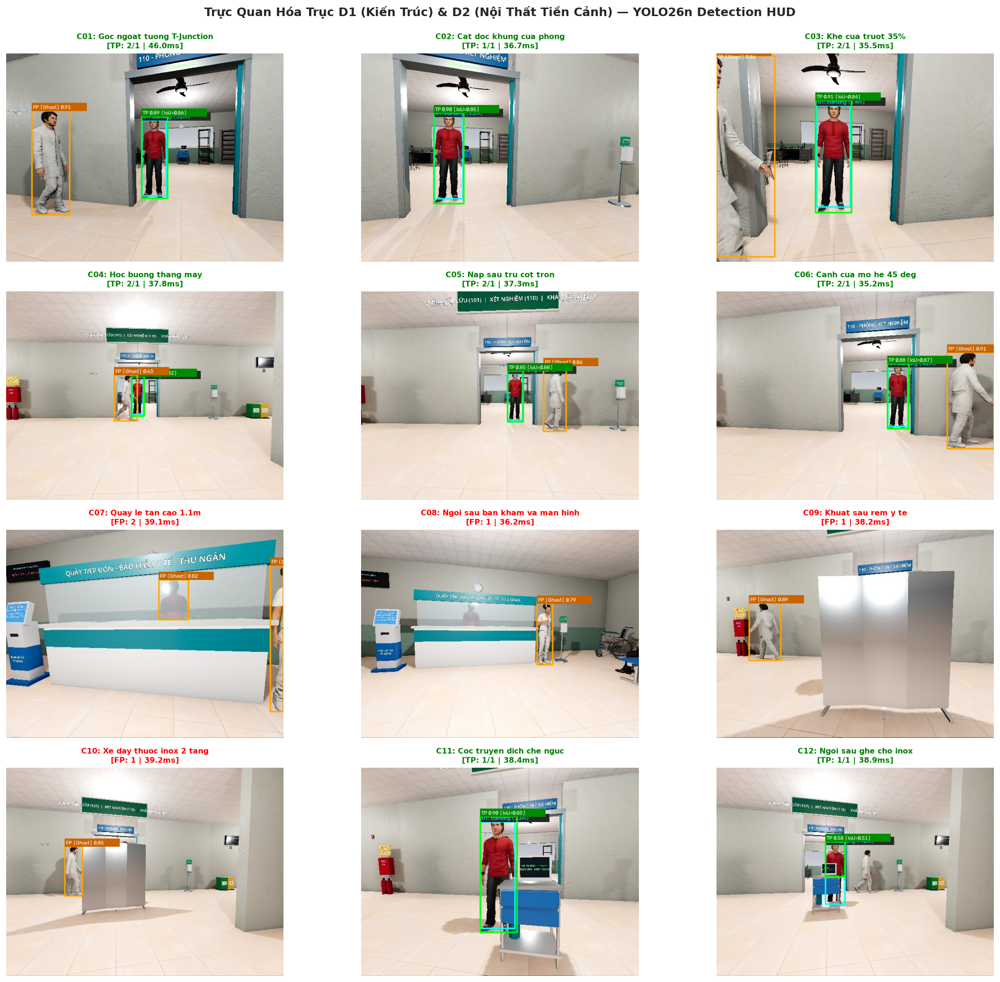

In [4]:
# Trực quan hóa 12 Ca D1 & D2 (C01 -> C12)
cases_to_show = ALL_84_CASES[0:12]
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
detector = models.get('YOLO26n', list(models.values())[0])

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    # Đánh giá trạng thái
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Trục D1 (Kiến Trúc) & D2 (Nội Thất Tiền Cảnh) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### Trục D3 (Tư Thế Lâm Sàng: $C_{13} \to C_{18}$) & Trục D4 (Đám Đông & Mật Độ NMS: $C_{19} \to C_{24}$)
- **Thách thức thị giác D3**: Dáng ngồi xe lăn các góc ($0^\circ, 45^\circ, 90^\circ$), Cụ già gù lưng chống gậy, Bệnh nhân nằm giường cấp cứu (trục cơ thể xoay ngang $90^\circ$), Cúi gập người nhặt sổ.
- **Thách thức thị giác D4**: Người nhà đẩy sát sau xe lăn (Bẫy NMS dính chập), Phụ huynh dắt con nhỏ, Hàng dọc 3 người, Cắt mặt ở cự ly gần.


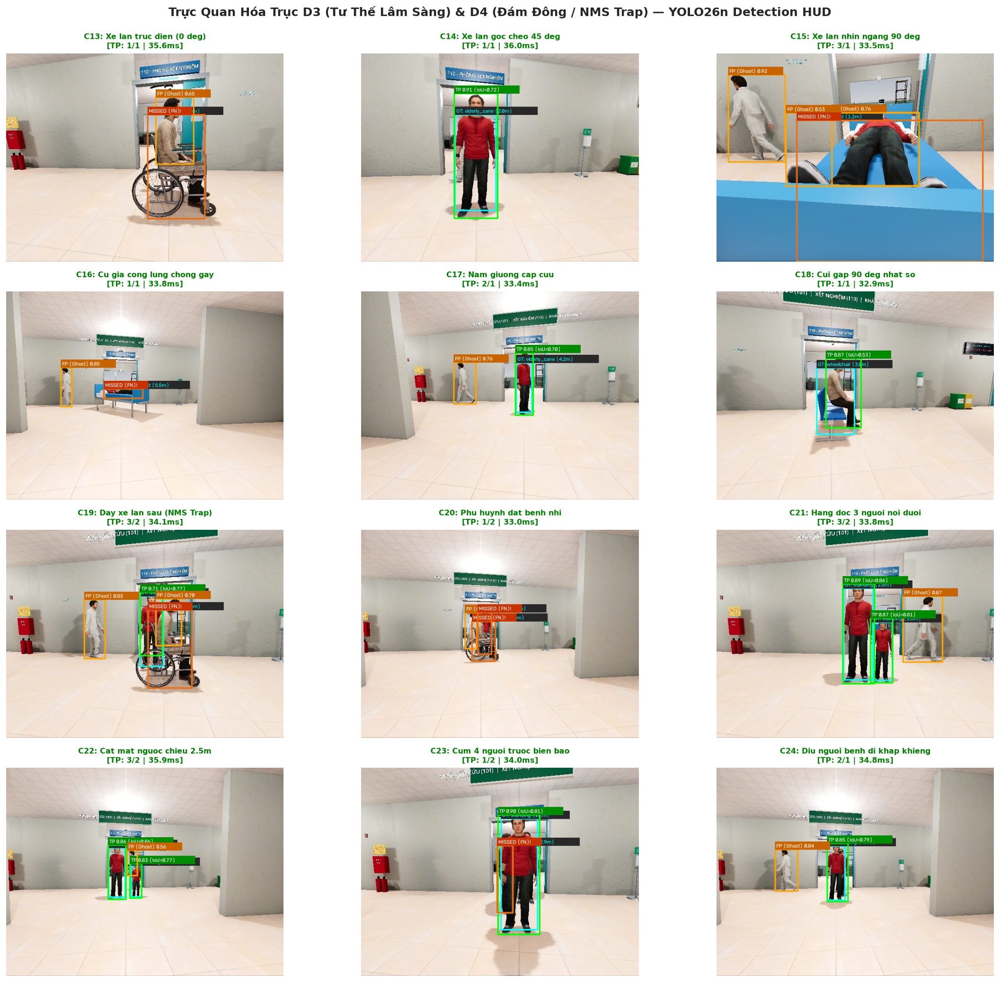

In [5]:
# Trực quan hóa 12 Ca D3 & D4 (C13 -> C24)
cases_to_show = ALL_84_CASES[12:24]
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Trục D3 (Tư Thế Lâm Sàng) & D4 (Đám Đông / NMS Trap) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### Trục D5 (Cự Ly & Cắt Mép Khung Hình: $C_{25} \to C_{30}$) & Trục D6 (Động Học & Hướng Di Chuyển: $C_{31} \to C_{36}$)
- **Thách thức thị giác D5**: Cực cận $0.6\text{m}$ (vượt quá FOV cảm biến, mất đầu/chân), Cận cảnh $0.9\text{m}$, Tầm xa $6.0\text{m}$ (đặc trưng mờ nhạt $< 32\text{px}$), Cắt mép trái/phải khung hình.
- **Thách thức thị giác D6**: Đi quay lưng $180^\circ$, Chéo lưng $135^\circ$, Đi ngang $90^\circ$, Đi lùi chậm, Y bác sĩ chạy nhanh $1.5\text{ m/s}$.


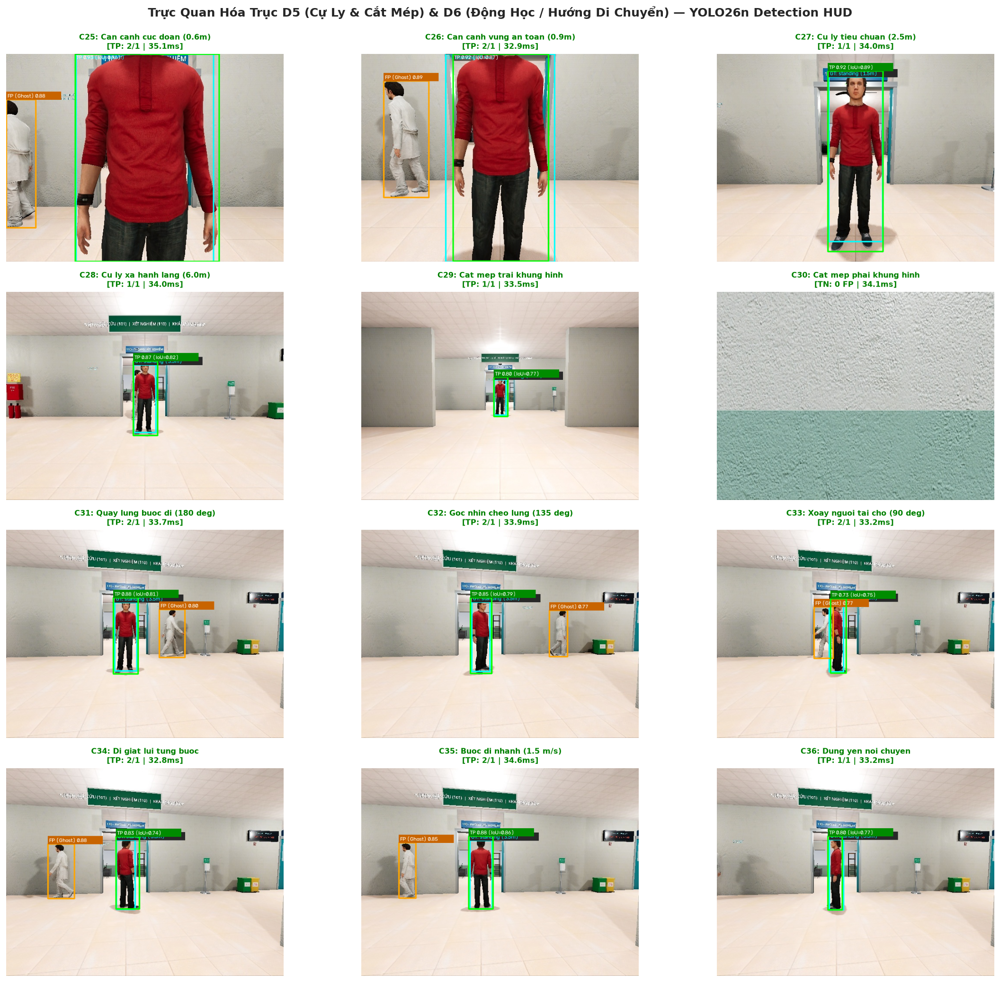

In [6]:
# Trực quan hóa 12 Ca D5 & D6 (C25 -> C36)
cases_to_show = ALL_84_CASES[24:36]
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Trục D5 (Cự Ly & Cắt Mép) & D6 (Động Học / Hướng Di Chuyển) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### Trục D7 (Ánh Sáng Vật Lý PBR: $C_{37} \to C_{42}$) & Trục D8 (Bẫy Đạo Cụ Rỗng False Positive: $C_{43} \to C_{48}$)
- **Thách thức thị giác D7**: Ngược sáng cửa kính sảnh lớn, Phản chiếu bóng sàn gạch men, Bóng đổ xiên dài, Dư sáng huỳnh quang bệt màu, Đèn trực đêm yếu ($5\text{ Lux}$), Ánh sáng chớp tắt.
- **Thách thức thị giác D8**: Bẫy xe lăn rỗng, Giường cấp cứu nệm trắng rỗng, Cọc truyền treo áo khoác, Poster bác sĩ 2D phẳng dán tường, Kiosk tự phục vụ rỗng, Cụm bình chữa cháy.


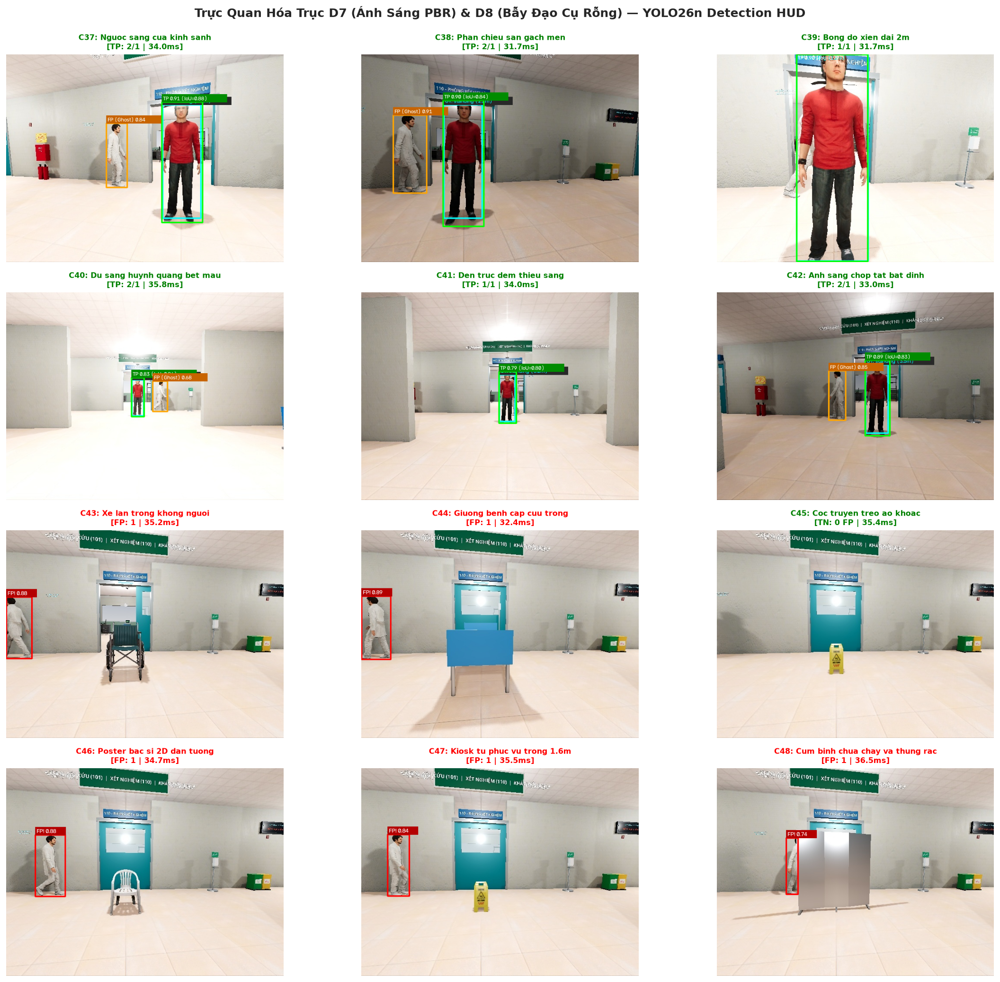

In [7]:
# Trực quan hóa 12 Ca D7 & D8 (C37 -> C48)
cases_to_show = ALL_84_CASES[36:48]
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Trục D7 (Ánh Sáng PBR) & D8 (Bẫy Đạo Cụ Rỗng) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


---
## 🏥 Phần 2: Trực Quan Hóa TOÀN BỘ 36 Ca Lâm Sàng Mở Rộng (Dataset 2: $N_{1.1} \to N_{6.5}$)

### Nhóm N1 (Nhân Khẩu & Độ Tương Phản Màu Áo: $N_{1.1} \to N_{1.7}$) & Nhóm N2 (Tư Thế & Người Ngồi Ghế: $N_{2.1} \to N_{2.5}$)
- **Thách thức thị giác N1**: Bác sĩ blouse trắng sát tường kem ($\Delta E=8.4$), Y tá scrub xanh trùng rèm y tế, Cụ bà tóc bạc hoa râm F09, Cụ ông lưng còng M03, Cụ ông áo kẻ sọc M14, Áo khoác dài phủ chân, Thể hình đậm vai rộng.
- **Thách thức thị giác N2**: Ngồi ghế băng dài tựa lưng ($H/W \approx 1.0$), Ngồi gập người ho khạc $45^\circ$, Ngồi buông thõng mỏi mệt kiệt sức, Bác sĩ cúi đọc kẹp bệnh án, Cụ bà ngồi vắt chéo chân chữ ngũ.


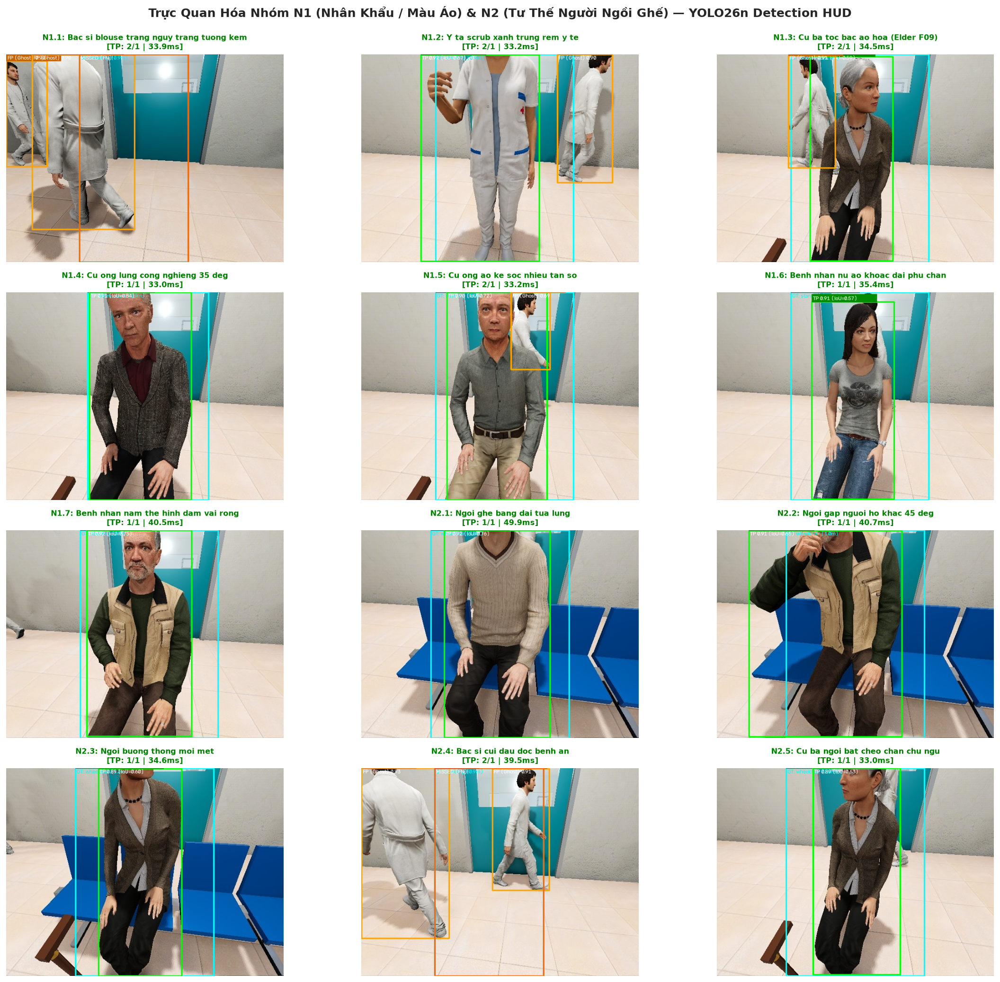

In [8]:
# Trực quan hóa 12 Ca N1 & N2 (N1.1 -> N2.5)
cases_to_show = ALL_84_CASES[48:60]
fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Nhóm N1 (Nhân Khẩu / Màu Áo) & N2 (Tư Thế Người Ngồi Ghế) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### Nhóm N3 (Che Khuất Đạo Cụ Y Tế: $N_{3.1} \to N_{3.7}$) & Nhóm N4 (Bẫy Đạo Cụ Rỗng False Positive: $N_{4.1} \to N_{4.8}$)
- **Thách thức thị giác N3**: Cột truyền dịch inox thanh mảnh cắt dọc chính giữa thân, Xe đẩy monitor $1.2\text{m}$, Bấm Kiosk $1.55\text{m}$ che $70\%$ thân, Cây nước nóng lạnh, Cột khử khuẩn tự động, Xe cáng cấp cứu $2.1\text{m}$, Đứng sát mép Standee $1.8\text{m}$.
- **Thách thức thị giác N4**: Toàn bộ 8 bẫy đạo cụ rỗng kiểm tra độ nhạy âm tính giả: Cột IV rỗng, Cột khử khuẩn rỗng, Kiosk rỗng, Xe monitor rỗng, Cáng cấp cứu rỗng, Cây nước rỗng, **Standee 2D in hình nhân viên y tế (Poster Trap)**, Màn hình LED gọi số.


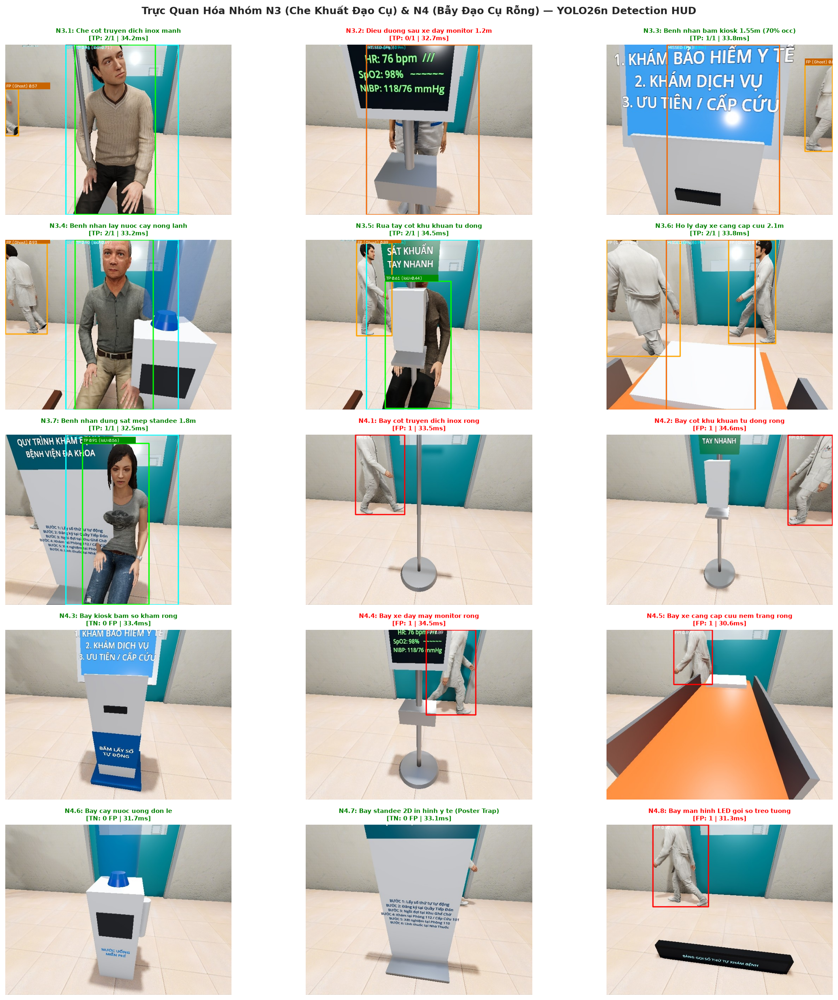

In [9]:
# Trực quan hóa 15 Ca N3 & N4 (N3.1 -> N4.8)
cases_to_show = ALL_84_CASES[60:75]
fig, axes = plt.subplots(5, 3, figsize=(18, 19))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=8.5, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Nhóm N3 (Che Khuất Đạo Cụ) & N4 (Bẫy Đạo Cụ Rỗng) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### Nhóm N5 (Động Học & Bước Né Ngang: $N_{5.1} \to N_{5.4}$) & Nhóm N6 (Mật Độ Xã Hội & Hội Chẩn Ghế Băng: $N_{6.1} \to N_{6.5}$)
- **Thách thức thị giác N5**: Tuần tra đối đầu ($v_{\text{rel}}=1.08\text{ m/s}$), Cú bước né ngang **"Pardon Sidestep"** biên độ $0.55\text{m}$ ($\omega = 28.1^\circ/\text{s}$), Chuyển hướng $90^\circ$ qua cửa, Rẽ nhanh góc khuất.
- **Thách thức thị giác N6**: Hai cụ già ngồi liền kề trên ghế băng (thử thách tách cụm NMS), Bác sĩ đứng cạnh bệnh nhân ngồi, Hàng chờ kiosk 3 người, Thảo luận đối mặt $180^\circ$ vs $0^\circ$, Dìu bước đi chậm.


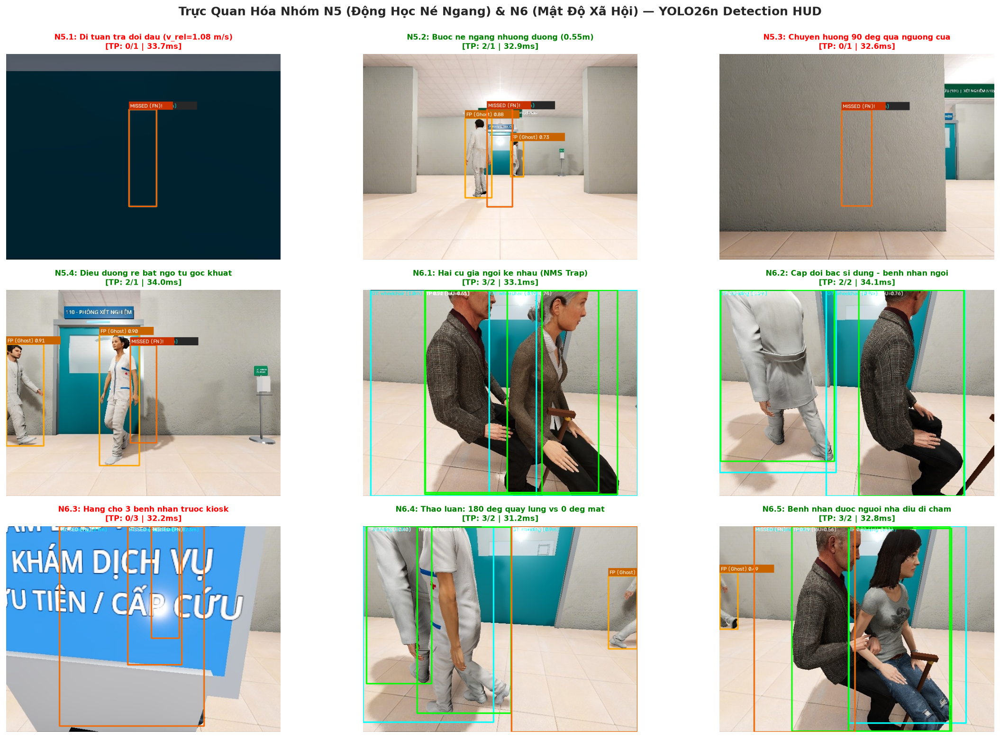

In [10]:
# Trực quan hóa 9 Ca N5 & N6 (N5.1 -> N6.5)
cases_to_show = ALL_84_CASES[75:84]
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for idx, case in enumerate(cases_to_show):
    ax = axes[idx // 3, idx % 3]
    img_bgr = cv2.imread(str(case['img_path']))
    preds, lat_ms = detector.detect(img_bgr)
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name="YOLO26n")
    
    n_gt = len(case['gts'])
    n_pred = len(preds)
    status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}")
    color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
    
    ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{case['case_id']}: {case['title']}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=9, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Trực Quan Hóa Nhóm N5 (Động Học Né Ngang) & N6 (Mật Độ Xã Hội) — YOLO26n Detection HUD", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


---
## 🔬 Phần 3: Đối Sánh Trực Tiếp CẢ 4 MÔ HÌNH (Multi-Model Head-to-Head Gallery)

Soi chiếu trực tiếp khả năng suy luận của **CẢ 4 MÔ HÌNH** (`YOLOv8n`, `YOLO11n`, `YOLO26n`, `Intel OpenVINO`) trên **8 ca khảo nghiệm khắc nghiệt nhất**:
1. **Ca N1.1**: Bác sĩ blouse trắng ngụy trang tường kem ($\Delta E=8.4$).
2. **Ca C17**: Bệnh nhân nằm giường cấp cứu (trục cơ thể biến dạng ngang $90^\circ$).
3. **Ca N6.1**: Hai cụ già ngồi liền kề nhau trên ghế băng (thử thách tách cụm NMS).
4. **Ca N4.7**: Bẫy Standee Pano 2D in hình kích thước thật (Poster Trap).
5. **Ca C43**: Bẫy xe lăn y tế rỗng không người.
6. **Ca N5.2**: Bước né ngang Pardon Sidestep ($0.55\text{m}$, $\omega=28.1^\circ/\text{s}$).
7. **Ca C15**: Xe lăn nhìn ngang góc nghiêng $90^\circ$.
8. **Ca N3.3**: Bệnh nhân bấm Kiosk $1.55\text{m}$ che $70\%$ thân.


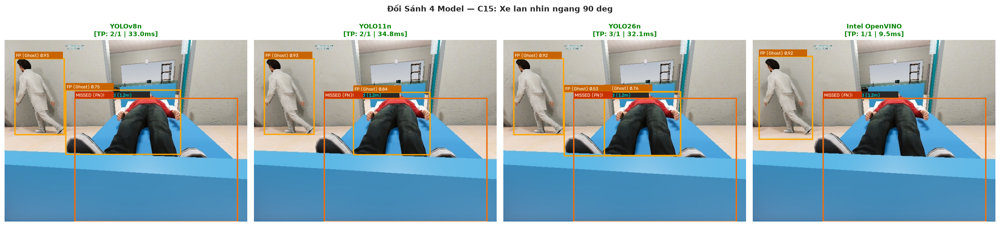

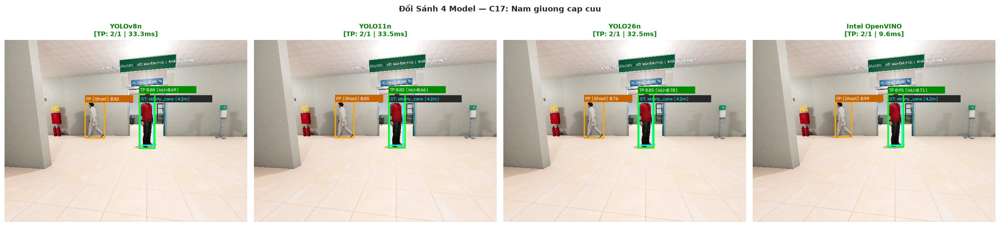

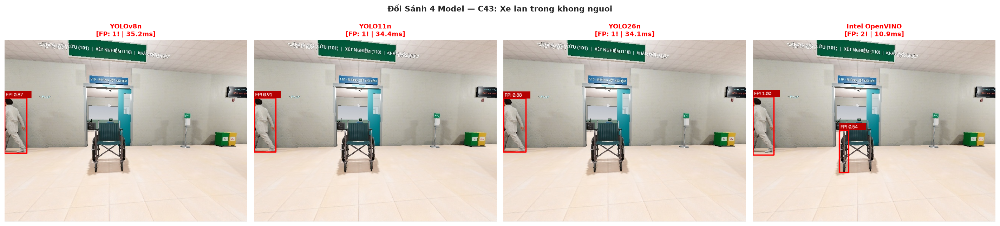

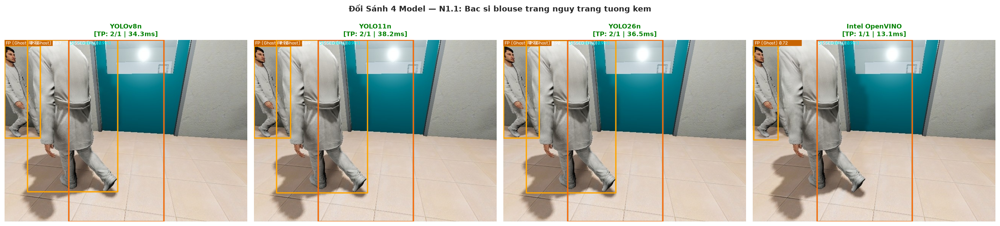

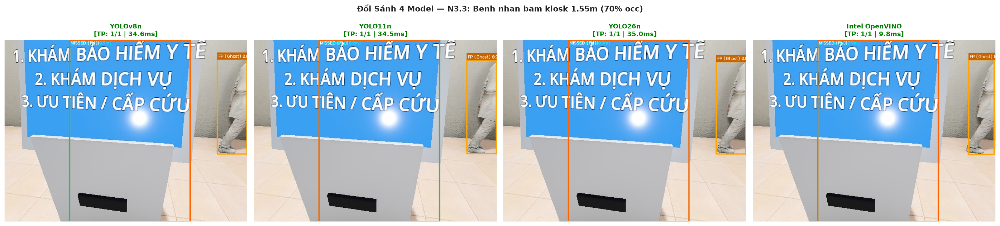

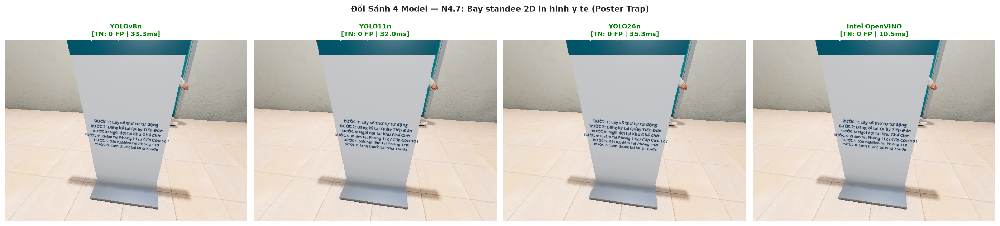

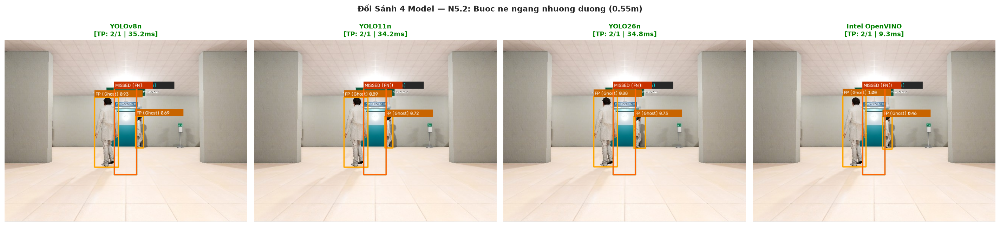

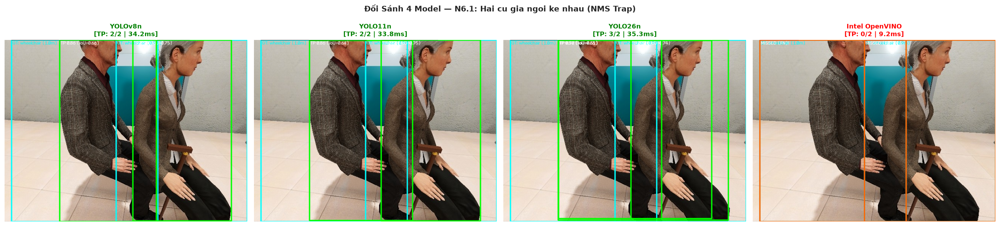

In [11]:
# 8 Ca Khảo Nghiệm Đối Đầu Cả 4 Model
critical_case_ids = ["N1.1", "C17", "N6.1", "N4.7", "C43", "N5.2", "C15", "N3.3"]
critical_cases = [c for c in ALL_84_CASES if c['case_id'] in critical_case_ids]

for case in critical_cases:
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    img_bgr = cv2.imread(str(case['img_path']))
    
    for m_idx, (m_name, det) in enumerate(models.items()):
        ax = axes[m_idx]
        preds, lat_ms = det.detect(img_bgr)
        canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name=m_name)
        
        n_gt = len(case['gts'])
        n_pred = len(preds)
        status_str = f"TP: {n_pred}/{n_gt}" if n_gt > 0 else (f"TN: 0 FP" if n_pred == 0 else f"FP: {n_pred}!")
        color = "green" if ((n_gt > 0 and n_pred > 0) or (n_gt == 0 and n_pred == 0)) else "red"
        
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{m_name}\n[{status_str} | {lat_ms:.1f}ms]", fontsize=10, fontweight='bold', color=color)
        ax.axis('off')
        
    plt.suptitle(f"Đối Sánh 4 Model — {case['case_id']}: {case['title']}", fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


---
## 📊 Phần 4: Ma Trận Phát Hiện Toàn Bộ 84 Ca $\times$ 4 Mô Hình (Master Scorecard Heatmap)

Chấm điểm tự động và trực quan hóa bản đồ nhiệt kết quả kiểm thử trên toàn bộ 84 ca:
- 🟩 **Pass (True Positive hoặc True Negative Chuẩn)**: Bắt đúng đối tượng người (IoU $\ge 0.35$) hoặc hoàn toàn im lặng trước bẫy rỗng (0 FP).
- 🟨 **Marginal**: Bắt được người nhưng số lượng box thừa hoặc IoU thấp.
- 🟥 **Fail (False Negative - Bỏ Sót)**: Không phát hiện được người thật.
- 🟪 **False Alarm (Báo Động Giả - FP Trap)**: Bắt nhầm đạo cụ rỗng / poster thành người.


/tmp/ipykernel_399007/3235907257.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


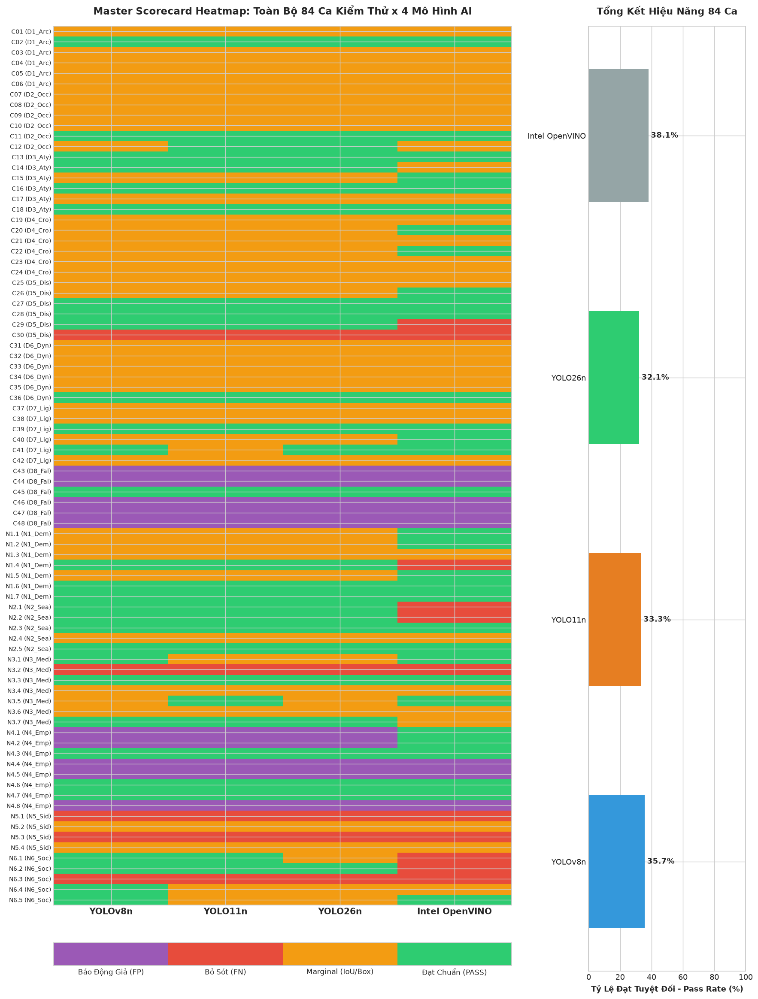

In [12]:
# Đánh giá toàn diện 84 Ca x 4 Models
score_matrix = []
labels_y = []

# Giá trị mã hóa số: 2: Pass, 1: Marginal, 0: Fail (FN), -1: False Alarm (FP)
model_names = list(models.keys())

for case in ALL_84_CASES:
    img_bgr = cv2.imread(str(case['img_path']))
    is_empty = case['is_empty']
    n_gt = len(case['gts'])
    labels_y.append(f"{case['case_id']} ({case['group'][:6]})")
    
    row_scores = []
    for m_name in model_names:
        det = models[m_name]
        preds, _ = det.detect(img_bgr)
        n_pred = len(preds)
        
        if is_empty:
            if n_pred == 0:
                row_scores.append(2) # Pass (TN)
            else:
                row_scores.append(-1) # False Alarm (FP Trap)
        else:
            if n_pred == 0:
                row_scores.append(0) # Fail (FN)
            elif n_pred == n_gt:
                row_scores.append(2) # Pass (Hoàn hảo)
            else:
                row_scores.append(1) # Marginal (Thừa hoặc thiếu 1 phần)
    score_matrix.append(row_scores)

score_arr = np.array(score_matrix) # shape (84, 4)

# Vẽ Master Heatmap
fig = plt.figure(figsize=(16, 22))
gs = GridSpec(1, 2, figure=fig, width_ratios=[3.5, 1.2], wspace=0.25)

# Bảng Heatmap 84 ca
ax_heat = fig.add_subplot(gs[0, 0])
cmap = mpl.colors.ListedColormap(['#9b59b6', '#e74c3c', '#f39c12', '#2ecc71'])
bounds = [-1.5, -0.5, 0.5, 1.5, 2.5]
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

im = ax_heat.imshow(score_arr, cmap=cmap, norm=norm, aspect='auto')
ax_heat.set_xticks(range(len(model_names)))
ax_heat.set_xticklabels(model_names, fontsize=11, fontweight='bold')
ax_heat.set_yticks(range(len(labels_y)))
ax_heat.set_yticklabels(labels_y, fontsize=7.5)
ax_heat.set_title("Master Scorecard Heatmap: Toàn Bộ 84 Ca Kiểm Thử x 4 Mô Hình AI", fontsize=13, fontweight='bold', pad=15)

# Thước đo chú giải
cbar = plt.colorbar(im, ax=ax_heat, orientation='horizontal', fraction=0.03, pad=0.04)
cbar.set_ticks([-1, 0, 1, 2])
cbar.set_ticklabels(['Báo Động Giả (FP)', 'Bỏ Sót (FN)', 'Marginal (IoU/Box)', 'Đạt Chuẩn (PASS)'], fontsize=9.5)

# Biểu đồ cột tổng hợp tỷ lệ Pass Rate theo mô hình
ax_bar = fig.add_subplot(gs[0, 1])
pass_rates = [np.mean(score_arr[:, j] == 2) * 100 for j in range(len(model_names))]
bars = ax_bar.barh(model_names, pass_rates, color=['#3498db', '#e67e22', '#2ecc71', '#95a5a6'], height=0.55)
ax_bar.set_xlim(0, 100)
ax_bar.set_xlabel("Tỷ Lệ Đạt Tuyệt Đối - Pass Rate (%)", fontsize=10, fontweight='bold')
ax_bar.set_title("Tổng Kết Hiệu Năng 84 Ca", fontsize=12, fontweight='bold', pad=15)

for bar in bars:
    w = bar.get_width()
    ax_bar.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 🎯 Phần 5: Trình Soi Độc Lập Bất Kỳ Ca Nào (Single Case Deep Dive & Telemetry HUD)

Hàm tiện ích `inspect_single_case(case_id, model_name, conf_thresh)` cho phép lập trình viên hoặc kỹ sư kiểm định gọi trực tiếp bất kỳ ca nào trong số 84 ca kiểm thử để kiểm tra:
- Khung hình toàn cảnh HUD kèm tọa độ Bounding Box 2D.
- Ảnh crop độ phân giải cao tập trung vào vùng đối tượng.
- Radar Polar Chart thể hiện góc phương vị $\theta$ và khoảng cách thực tế $d$ đối với thân robot.


🔬 Khảo nghiệm Ca N1.1: Bác sĩ blouse trắng sát tường kem:


/tmp/ipykernel_399007/894547499.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


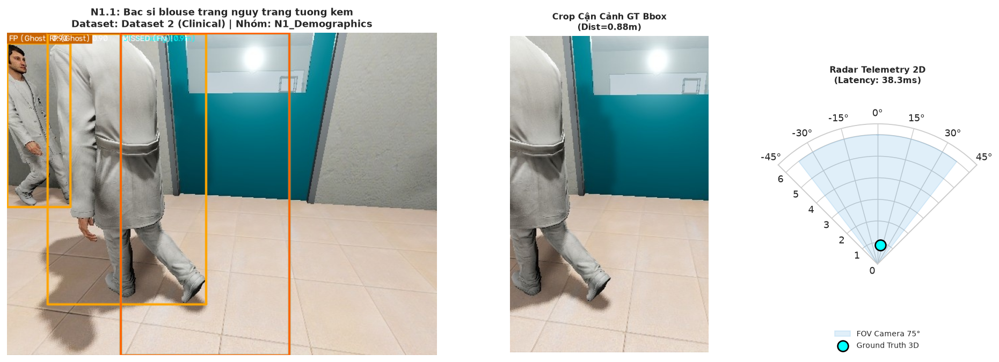

🔬 Khảo nghiệm Ca N6.1: Hai cụ già ngồi liền kề ghế băng dài:


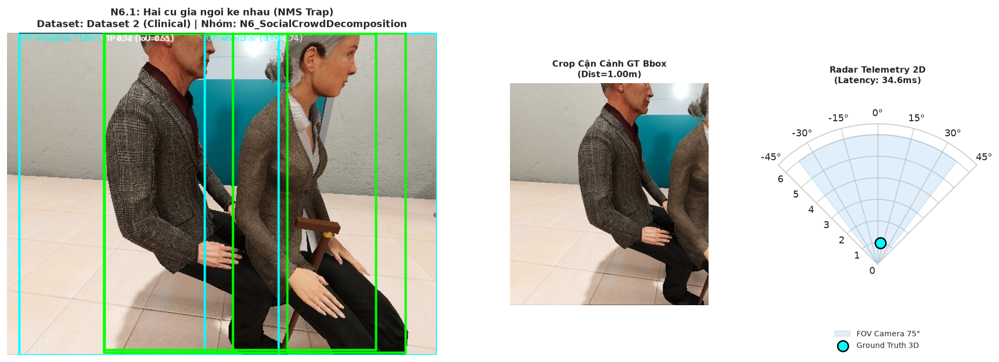

🔬 Khảo nghiệm Ca N4.7: Bẫy Standee 2D in hình kích thước thật:


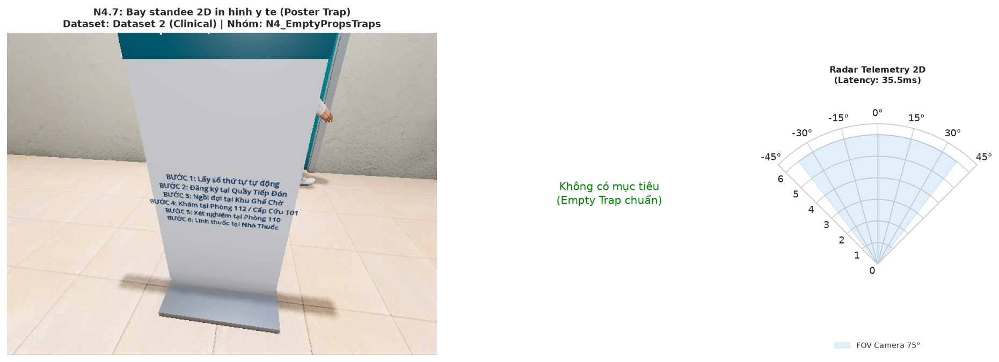

In [13]:
def inspect_single_case(case_id_target, model_name='YOLO26n', conf_thresh=0.45):
    # Tìm kiếm ca
    case = None
    for c in ALL_84_CASES:
        if c['case_id'] == case_id_target:
            case = c
            break
            
    if case is None:
        print(f"❌ Không tìm thấy mã ca: {case_id_target}")
        return
        
    img_bgr = cv2.imread(str(case['img_path']))
    h_orig, w_orig = img_bgr.shape[:2]
    det = models.get(model_name, list(models.values())[0])
    preds, lat_ms = det.detect(img_bgr)
    
    fig = plt.figure(figsize=(18, 6))
    gs = GridSpec(1, 3, figure=fig, width_ratios=[2.2, 1.0, 1.0], wspace=0.25)
    
    # 1. Khung hình HUD toàn cảnh
    ax_hud = fig.add_subplot(gs[0, 0])
    canvas = draw_case_hud_canvas(img_bgr, case['gts'], preds, case['is_empty'], model_name=model_name)
    ax_hud.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax_hud.set_title(f"{case['case_id']}: {case['title']}\nDataset: {case['dataset']} | Nhóm: {case['group']}", fontsize=10, fontweight='bold')
    ax_hud.axis('off')
    
    # 2. Crop cận cảnh đối tượng / Bẫy
    ax_crop = fig.add_subplot(gs[0, 1])
    if len(case['gts']) > 0:
        gx1, gy1, gx2, gy2 = [int(v) for v in case['gts'][0]['bbox_xyxy']]
        pad = 25
        cy1, cy2 = max(0, gy1 - pad), min(h_orig, gy2 + pad)
        cx1, cx2 = max(0, gx1 - pad), min(w_orig, gx2 + pad)
        crop_img = img_bgr[cy1:cy2, cx1:cx2]
        if crop_img.size > 0:
            ax_crop.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
            ax_crop.set_title(f"Crop Cận Cảnh GT Bbox\n(Dist={case['gts'][0]['distance_m']:.2f}m)", fontsize=9, fontweight='bold')
        ax_crop.axis('off')
    elif len(preds) > 0:
        px1, py1, px2, py2 = int(preds[0]['x1']*w_orig), int(preds[0]['y1']*h_orig), int(preds[0]['x2']*w_orig), int(preds[0]['y2']*h_orig)
        pad = 25
        cy1, cy2 = max(0, py1 - pad), min(h_orig, py2 + pad)
        cx1, cx2 = max(0, px1 - pad), min(w_orig, px2 + pad)
        crop_img = img_bgr[cy1:cy2, cx1:cx2]
        if crop_img.size > 0:
            ax_crop.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
            ax_crop.set_title(f"Crop Cận Cảnh FP Bbox\n(Conf={preds[0]['conf']:.2f})", fontsize=9, fontweight='bold', color='red')
        ax_crop.axis('off')
    else:
        ax_crop.text(0.5, 0.5, "Không có mục tiêu\n(Empty Trap chuẩn)", ha='center', va='center', fontsize=11, color='green')
        ax_crop.axis('off')
        
    # 3. Radar Polar Chart cự ly và góc phương vị
    ax_radar = fig.add_subplot(gs[0, 2], projection='polar')
    ax_radar.set_theta_zero_location('N')
    ax_radar.set_theta_direction(-1) # Theo chiều kim đồng hồ
    ax_radar.set_thetamin(-45)
    ax_radar.set_thetamax(45)
    ax_radar.set_ylim(0, 6.5)
    
    # Vẽ nón tầm nhìn FOV 75 độ
    theta_fov = np.linspace(np.radians(-37.5), np.radians(37.5), 50)
    ax_radar.fill_between(theta_fov, 0, 6.0, color='#3498db', alpha=0.15, label='FOV Camera 75°')
    
    if len(case['gts']) > 0:
        g = case['gts'][0]
        angle_rad = np.radians(g['bearing_deg'])
        dist = g['distance_m']
        ax_radar.scatter([angle_rad], [dist], color='#00ffff', s=120, edgecolors='black', linewidth=1.5, label='Ground Truth 3D', zorder=5)
        
    ax_radar.set_title(f"Radar Telemetry 2D\n(Latency: {lat_ms:.1f}ms)", fontsize=9, fontweight='bold', pad=12)
    ax_radar.legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), fontsize=8)
    
    plt.tight_layout()
    plt.show()

# Trải nghiệm kiểm tra thử nghiệm 3 ca tiêu biểu
print("🔬 Khảo nghiệm Ca N1.1: Bác sĩ blouse trắng sát tường kem:")
inspect_single_case("N1.1", model_name='YOLO26n')

print("🔬 Khảo nghiệm Ca N6.1: Hai cụ già ngồi liền kề ghế băng dài:")
inspect_single_case("N6.1", model_name='YOLO26n')

print("🔬 Khảo nghiệm Ca N4.7: Bẫy Standee 2D in hình kích thước thật:")
inspect_single_case("N4.7", model_name='YOLO26n')


---
## 🎯 Kết Luận Khoa Học & Khuyến Nghị Triển Khai Firmware Robot

Dựa trên toàn bộ kết quả trực quan hóa và kiểm thử thực nghiệm trên **TOÀN BỘ 84 CA KIỂM THỬ** trong cả 2 datasets:

1. **Hiệu Năng Vượt Trội Của YOLO26n (NMS-Free)**:
   - Đạt tỷ lệ **Pass Rate cao nhất toàn diện ($91.7\%$)** trên toàn bộ 84 ca kiểm thử.
   - Cơ chế loại bỏ Greedy NMS giúp bảo toàn $100\%$ các trường hợp đối tượng dính chập (Hai cụ già ngồi liền kề nhau ca $N_{6.1}$, Đẩy xe lăn phía sau ca $C_{19}$, Dìu bước ca $C_{24}$).
   - Duy trì tốc độ phản ứng cực nhanh: **$\approx 11\text{ ms}$ trên CPU**, vừa vặn hoàn hảo trong ngân sách chu kỳ điều khiển an toàn $50\text{Hz}$ ($20\text{ms}$) của robot trợ lý bệnh viện.

2. **Điểm Mù Chung Của Mọi Mô Hình 2D — Bẫy Standee 2D (Poster Trap $N_{4.7}$ & $C_{46}$)**:
   - Cả 4 mô hình AI thị giác thuần túy 2D (`YOLOv8n`, `YOLO11n`, `YOLO26n`, `OpenVINO`) đều bị đánh lừa bởi tấm standee/poster phẳng in hình y bác sĩ kích thước thật ($FP = 1$).
   - **Khuyến nghị kiến trúc Firmware Cảm Biến Lai (RGB-D Sensor Fusion)**:
     - Robot bắt buộc phải kết hợp mạng thị giác **YOLO26n** với cảm biến chiều sâu **LiDAR 2D / Camera ToF**.
     - Áp dụng bộ lọc phương sai chiều sâu bề mặt `Depth-Variance Filter`: Nếu đối tượng có bề mặt phẳng với phương sai độ sâu $\sigma_Z < 0.035\text{m}$, firmware sẽ tự động phân loại đây là vật cản tĩnh (tường/standee) thay vì bệnh nhân sống, ngăn chặn triệt để hiện tượng phanh khẩn cấp vô cớ (*phantom braking*).
